In [17]:
#Import packages used
import matplotlib
import matplotlib.pyplot as plt
import numpy as np

#Load custom module
from os.path import dirname, abspath
d = dirname(abspath(""))
import sys
sys.path.append(d + '\\EOsimSuite')
from EOsimsuite import EOsimsuite as EOsim

In [19]:
#Sensitivity function - rs are resource concs, specInd is the index of the species under consideration, C is the consumption matrix, delW is the resource values and D is the mortality rate
def sensFunc(rs,specInd,EOparams):
    ws = EOparams['ws']
    ps = EOparams['ps']
    
    return sum([rs[rho]*ps[specInd,rho]*ws[rho] for rho in range(len(rs))])

def gradSensFunc(rs,specInd,EOparams):
    ws = EOparams['ws']
    ps = EOparams['ps']

    return(np.array([ps[specInd,rho]*ws[rho] for rho in range(len(rs))]))

#Impact function for a single species
def impactFunc(rs,specInd,EOparams):
    ps = EOparams['ps']
    
    impact = np.array([-ps[specInd,rho]*rs[rho] for rho in range(len(rs))])

    return impact

def instInteract(rs,alphInd,betInd,EOparams):
    return(np.dot(impactFunc(rs,betInd,EOparams),gradSensFunc(rs,alphInd,EOparams)))

def intrinsicGR(rs,specInd,EOparams,sysParams):
    vs = sysParams['vs']
    Ks = sysParams['Ks']
    ts = sysParams['ts']

    ps = EOparams['ps']
    ws = EOparams['ws']
    
    intGR = sum([ws[rho]*ps[specInd,rho]*rs[rho]*vs[rho]*(Ks[rho] - rs[rho])/Ks[rho] for rho in range(len(rs))])
    
    return intGR

In [21]:
#Functions that generate random parameter matrices
def genRandMats(noSpec,noRes):
    Pvar = 0.5 #Variation of resource preferences
    Pmin = 0 #Minimum resource preference
    Wvar = 0.5
    Wmin = 0
    
    ps = Pmin + np.random.rand(noSpec,noRes)*Pvar
    ws = Wmin + np.random.rand(noRes)*Wvar
    
    return (ps,ws)

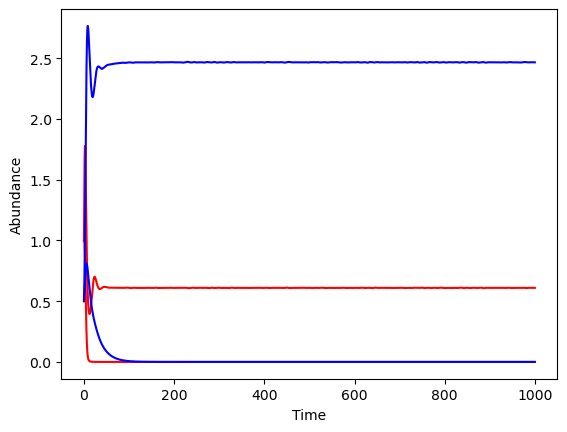

In [31]:
#This script generates a random realisation of a two-population MacArthur model
noSpec = 2
noRes = 2

Ks = np.array([2,3])
vs = np.array([0.8,1.2])
ts = np.array([0.1,0.08])

sysParams = {'Ks':Ks,'vs':vs,'ts':ts}

B0 = np.ones((noSpec,))*0.5 #Starting concentration of bacteria in batch (biomass)
R0 = np.ones((noRes,))

(ps,ws) = genRandMats(noSpec,noRes)
EOparams = {'ps':ps,'ws':ws}
    
macSimBase = EOsim(impactFunc,sensFunc,EOparams,sysParams,B0,R0)
macSimBase.set_timeSettings(tSpan = [0,1000], dt=0.1)
macSimBase.set_instInteract(instInteract)
macSimBase.set_intrinsicGR(intrinsicGR)

macSimBase.simEOmodel('MacArthur')

coexists = sum(macSimBase.specTimeseries[:,-1] > 0.1)

macSimBase.plotSolutionTimecourse()